# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Botron, Christan Jake
- _Student No._: 2024-10168
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="errorconvg.png" alt="Alt text" width=80%> 

**Figure 1.** Numerical integration error convergence showing the absolute error scaling of the Monte Carlo and Newton-Cotes methods.

<img src="montecarlo.png" alt="Alt text" width=80%>

**Figure 2.** Monte Carlo simulation of the three test functions, mapping the positive (blue) and negative (red) geometric area contributions at a sample size of $N = 10,000$. 



### Report discussion

In Figure 1, the error convergence plots show Newton-Cotes methods exhibiting a rapid, linear decline in absolute error on a log-log scale, reflecting higher-order deterministic convergence. Simpson’s error for $f_2$ immediately flatlines near machine precision, intrinsically reconstructing the underlying parabola. Conversely, Monte Carlo error displays a highly volatile, slower stochastic convergence. Figure 2 visualizes a Monte Carlo integration by using discrete points, distinguishing positive (blue) and negative (red) geometric area contributions. Monte Carlo integration values are derived using the Law of Large Numbers where the proportion of random points bounded by the curve relative to a bounding box geometrically converges to the true area ratio (refer to the formula in my top comment for the MC integration section). That is, if you randomly scatter points across a rectangular box, simply counting the fraction of points that "hit" the target curve should give you the curve's area given many points (like N = 10000). Newton-Cotes methods are mathematically superior for smooth, low-dimensional integrands due to exceptional computational efficiency. However, grid-based intervals suffer from the curse of dimensionality, making MC methods strictly more appropriate for evaluating highly complex, multi-dimensional systems.

### Other comments
- I have no other comments.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [9]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

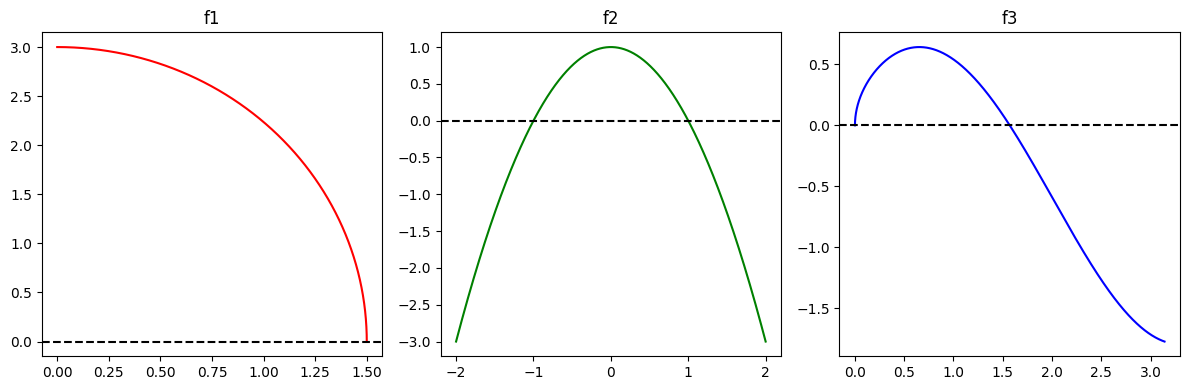

In [76]:
#functions definition
#sir andito ang definitions ng f1, f2, at f3

N = 600000

def f1(x):
    return np.sqrt(9 - 4*x**2)
    
a1 = 0
b1 = 3/2
x1 = np.linspace(0,3/2,N)

def f2(x):
    return -x**2 + 1

a2 = -2
b2 = 2
x2 = np.linspace(-2,2,N)

def f3(x):
    return np.cos(x)*np.sqrt(x)
    
a3 = 0
b3 = np.pi
x3 = np.linspace(0,np.pi,N)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Plot on each axis
axes[0].plot(x1, f1(x1), label="f1", color="red", linestyle="-")
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("f1")

axes[1].plot(x2, f2(x2), label="f2", color="green", linestyle="-")
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title("f2")

axes[2].plot(x3, f3(x3), label="f3", color="blue", linestyle="-")
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set_title("f3")

plt.tight_layout()
plt.show()

In [66]:
#----------------------------------------------------------------------------------------------------------------------#
#expected results

print(f"{quad(f1,a1,b1)[0]:.6f}")
print(f"{quad(f2,a2,b2)[0]:.6f}")
print(f"{quad(f3,a3,b3)[0]:.6f}")

3.534292
-1.333333
-0.894831


In [67]:
#----------------------------------------------------------------------------------------------------------------------#
#monte carlo integration - (b-a)*(1/N)*[sum from i=1->N of f(xi)]

def montecarlo_int(f,a,b,N):
    
    x_random = np.random.uniform(a, b, N)
    return (b - a) * np.mean(f(x_random))

print(f"Monte Carlo Integration:")
print(f"{montecarlo_int(f1,a1,b1,N):.6f}")
print(f"{montecarlo_int(f2,a2,b2,N):.6f}")
print(f"{montecarlo_int(f3,a3,b3,N):.6f}")

Monte Carlo Integration:
3.531650
-1.331075
-0.897768


In [68]:
#----------------------------------------------------------------------------------------------------------------------#
#trapezoidal integration - h * [f(a) + 2*(SUM from i=1->n-1 f(a+ih) + f(b)] / 2 ; h = (b-a)/N

def trapezoidal_int(f, a, b, N):
    x = np.linspace(a, b, N+1)
    y = f(x)
    h = (b-a) / N
    return (h / 2) * (y[0] + 2 * np.sum(y[1:-1]) + y[-1])

print(f"Trapezoidal Integration:")
print(f"{trapezoidal_int(f1,a1,b1,N):.6f}")
print(f"{trapezoidal_int(f2,a2,b2,N):.6f}")
print(f"{trapezoidal_int(f3,a3,b3,N):.6f}")

Trapezoidal Integration:
3.534292
-1.333333
-0.894831


In [69]:
#----------------------------------------------------------------------------------------------------------------------#
#simpson's 1/3 rule - h/3 * [f(x0) + 4f(x1) + 2f(x2) + 4f(x3) + 2f(x4) + ... + 4f(x_n-1) + f(x_n)]

def simpson_third_int(f,a,b,N):
    if N % 2 != 0:
        print("N must even!")
    else:
        x = np.linspace(a, b, N + 1)
        y = f(x)
        h = (b - a) / N
        return (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1]) #y[1:-1:2] gets the odd indices, while y[2:-2:2] gets the even indices (w3schools ftw)

print(f"Simpson's One-Third Rule Integration:")
print(f"{simpson_third_int(f1,a1,b1,N):.6f}")
print(f"{simpson_third_int(f2,a2,b2,N):.6f}")
print(f"{simpson_third_int(f3,a3,b3,N):.6f}")

Simpson's One-Third Rule Integration:
3.534292
-1.333333
-0.894831


In [70]:
#----------------------------------------------------------------------------------------------------------------------#
#simpson's 3/8 rule - 3h/8 * [f(x0) + 3f(x1) + 3f(x2) + 2f(x3) + 3f(x4) + 3f(x5) + 2f(x6) + ... + f(x_n)]

def simpson_three_eight_int(f, a, b, N):
    if N % 3 != 0:
        print("N must be a multiple of 3")
    else:
        x = np.linspace(a, b, N + 1)
        y = f(x)
        h = (b - a) / N
        return (3 * h / 8) * (y[0] + 3 * np.sum(y[1:-1:3]) + 3 * np.sum(y[2:-1:3]) + 2 * np.sum(y[3:-1:3]) + y[-1]) 
#                                            1,4,7,...                2,5,8,...              3,6,9,...
    
print(f"Simpson's Three-Eigth Rule Integration:")
print(f"{simpson_three_eight_int(f1,a1,b1,N):.6f}")
print(f"{simpson_three_eight_int(f2,a2,b2,N):.6f}")
print(f"{simpson_three_eight_int(f3,a3,b3,N):.6f}")

Simpson's Three-Eigth Rule Integration:
3.534292
-1.333333
-0.894831


In [71]:
#----------------------------------------------------------------------------------------------------------------------#
#total area
def total_area(f, a, b, N, integration_method):
    f_abs = lambda x: np.abs(f(x))
    
    return integration_method(f_abs, a, b, N)

print("Total Area of f1, f2, f3 in order")
print("------------------")
print("Monte Carlo")
print(total_area(f1, a1, b1, N, montecarlo_int))
print(total_area(f2, a2, b2, N, montecarlo_int))
print(total_area(f3, a3, b3, N, montecarlo_int))
print("------------------")
print("Trapezoid")
print(total_area(f1, a1, b1, N, trapezoidal_int))
print(total_area(f2, a2, b2, N, trapezoidal_int))
print(total_area(f3, a3, b3, N, trapezoidal_int))
print("------------------")
print("Simpson's 1/3")
print(total_area(f1, a1, b1, N, simpson_third_int))
print(total_area(f2, a2, b2, N, simpson_third_int))
print(total_area(f3, a3, b3, N, simpson_third_int))
print("------------------")
print("Simpson's 3/8")
print(total_area(f1, a1, b1, N, simpson_three_eight_int))
print(total_area(f2, a2, b2, N, simpson_three_eight_int))
print(total_area(f3, a3, b3, N, simpson_three_eight_int))

Total Area of f1, f2, f3 in order
------------------
Monte Carlo
3.5347003649622555
4.003052765035259
2.3050344534826284
------------------
Trapezoid
3.5342917324419183
4.0
2.302906971155012
------------------
Simpson's 1/3
3.5342917341768514
3.9999999999999996
2.3029069726781235
------------------
Simpson's 3/8
3.5342917339350133
3.9999999999999996
2.3029069724665203


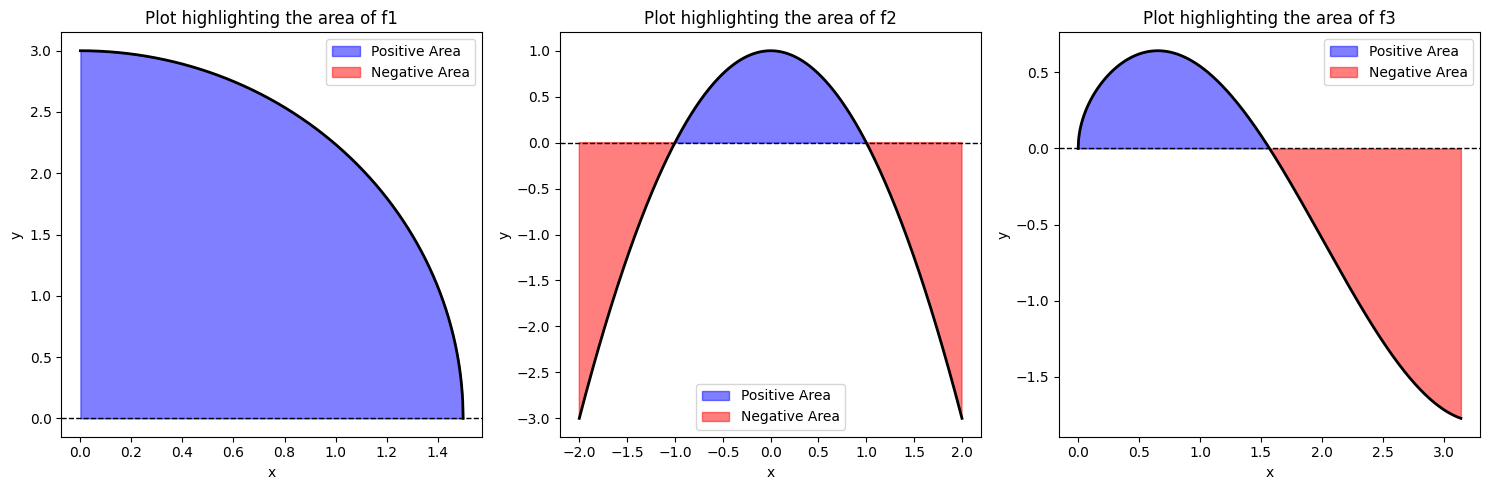

Signed Area (Integral)
f1: 3.534292
f2: -1.333333
f3: -0.894831
------------------
Total Area (Absolute Area)
f1: 3.534292
f2: 4.000000
f3: 2.302907


In [72]:
#--------------------------------------------------------------------------#
#area graphing (total and signed) using scipy for checking

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
functions = [(f1, a1, b1, "f1"), (f2, a2, b2, "f2"), (f3, a3, b3, "f3")]

for i, (f, a, b, name) in enumerate(functions):
    x = np.linspace(a, b, 1000)
    y = f(x)
    
    signed_area = quad(f, a, b)[0] #normal integral (process is the same as above)
    
    f_abs = lambda x_val: np.abs(f(x_val)) 
    total_area = quad(f_abs, a, b)[0] #abs value to get total area (process is the same as above)
    
    axes[i].plot(x, y, color="black", linewidth=2)
    axes[i].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[i].fill_between(x, y, 0, where=(y >= 0), color='blue', alpha=0.5, label='Positive Area')
    axes[i].fill_between(x, y, 0, where=(y < 0), color='red', alpha=0.5, label='Negative Area')
    axes[i].set_title(f"Plot highlighting the area of {name}")
    axes[i].set_xlabel("x")
    axes[i].set_ylabel("y")
    axes[i].legend(loc="best")

plt.tight_layout()
plt.show()

print("Signed Area (Integral)")
for f, a, b, name in functions:
    print(f"{name}: {quad(f, a, b)[0]:.6f}")
print("------------------")
print("Total Area (Absolute Area)")
for f, a, b, name in functions:
    f_abs = lambda x_val: np.abs(f(x_val))
    print(f"{name}: {quad(f_abs, a, b)[0]:.6f}")

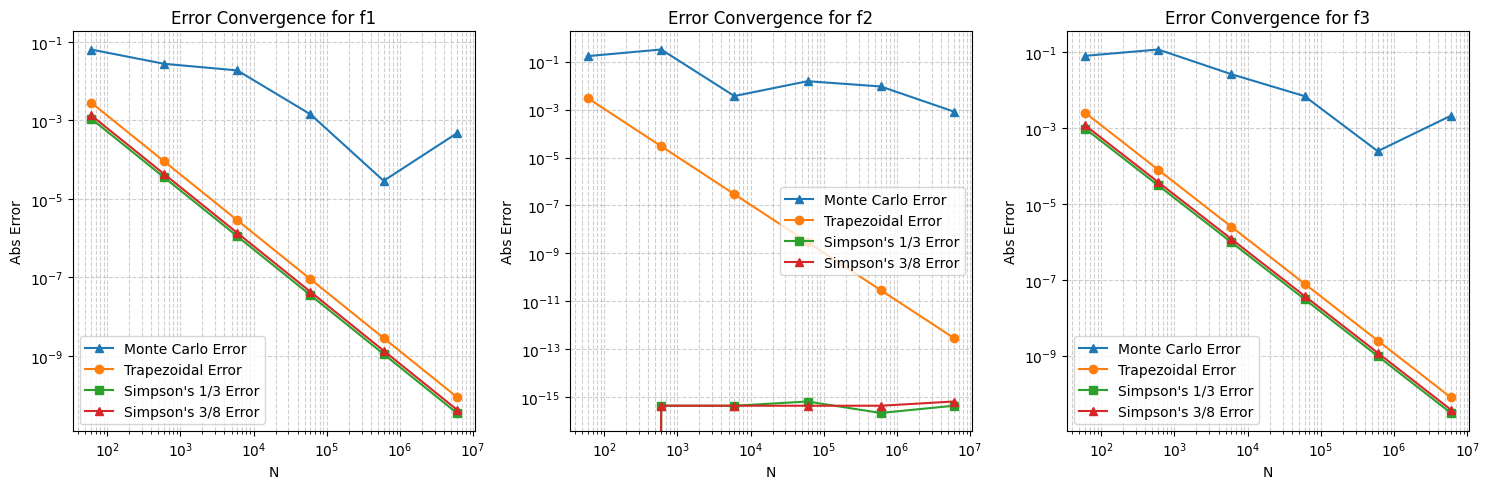

In [77]:
#--------------------------------------------------------------------------#
#error convergence plotting

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
functions = [(f1, a1, b1, "f1"), (f2, a2, b2, "f2"), (f3, a3, b3, "f3")]
N_values = np.array([60, 600, 6000, 60000, 600000, 6000000]) #i used this so we can satisfy the requirements for both simpson's rules

for i, (f, a, b, name) in enumerate(functions):
    true_val = quad(f, a, b)[0] 
    
    err_mc = []
    err_trap = []
    err_simp13 = []
    err_simp38 = []
    
    for n in N_values:
        err_mc.append(np.abs(montecarlo_int(f, a, b, n) - true_val))
        err_trap.append(np.abs(trapezoidal_int(f, a, b, n) - true_val))
        err_simp13.append(np.abs(simpson_third_int(f, a, b, n) - true_val))
        err_simp38.append(np.abs(simpson_three_eight_int(f, a, b, n) - true_val))
        
    axes[i].loglog(N_values, err_mc, '^-', label="Monte Carlo Error")
    axes[i].loglog(N_values, err_trap, 'o-', label="Trapezoidal Error")
    axes[i].loglog(N_values, err_simp13, 's-', label="Simpson's 1/3 Error")
    axes[i].loglog(N_values, err_simp38, '^-', label="Simpson's 3/8 Error")
    
    axes[i].set_title(f"Error Convergence for {name}")
    axes[i].set_xlabel("N")
    axes[i].set_ylabel("Abs Error")
    axes[i].legend(loc="best")
    axes[i].grid(True, which="both", ls="--", alpha=0.6)

plt.tight_layout()
plt.savefig("errorconvg.png")
plt.show()

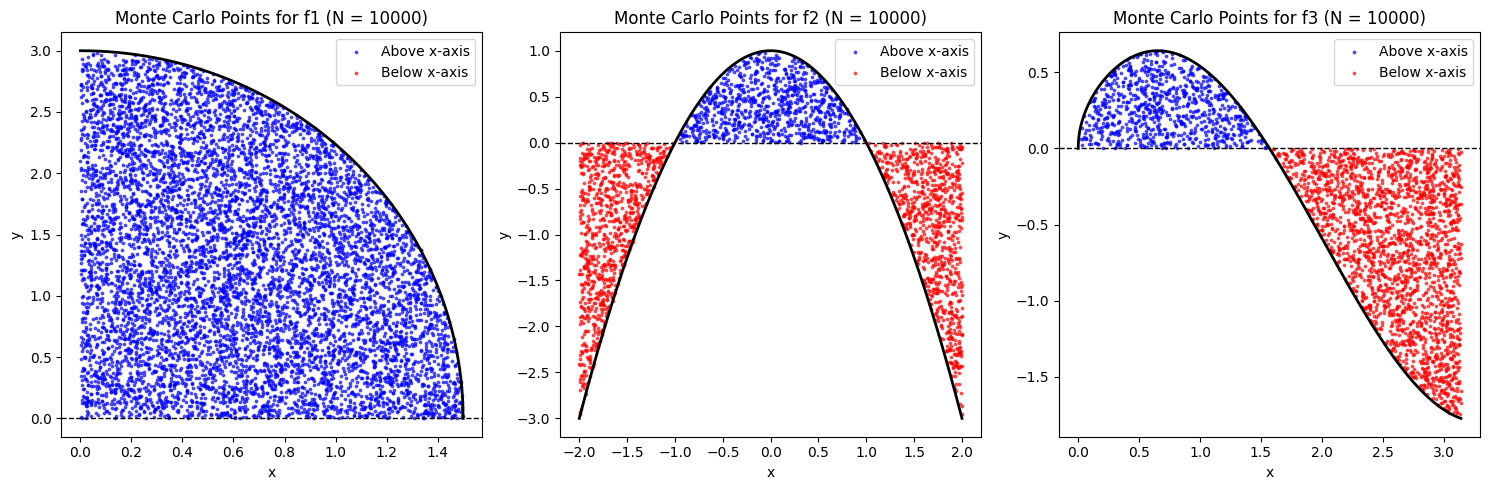

In [79]:
#--------------------------------------------------------------------------#
#monte carlo simulation thingy

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
functions = [(f1, a1, b1, "f1"), (f2, a2, b2, "f2"), (f3, a3, b3, "f3")]
N_mc = 10000 

for i, (f, a, b, name) in enumerate(functions):
    x = np.linspace(a, b, 1000)
    y = f(x)
    y_min = min(0, np.min(y)) #define bounds
    y_max = max(0, np.max(y))
    x_rand = np.random.uniform(a, b, N_mc) #random points inside bounds
    y_rand = np.random.uniform(y_min, y_max, N_mc)
    y_actual = f(x_rand)
    
    blue_mask = (y_rand >= 0) & (y_rand <= y_actual) #masks 
    red_mask = (y_rand < 0) & (y_rand >= y_actual)
    axes[i].plot(x, y, color="black", linewidth=2, zorder=3)
    axes[i].axhline(0, color='black', linestyle='--', linewidth=1, zorder=3)
    axes[i].scatter(x_rand[blue_mask], y_rand[blue_mask], color='blue', s=3, alpha=0.6, label='Above x-axis')
    axes[i].scatter(x_rand[red_mask], y_rand[red_mask], color='red', s=3, alpha=0.6, label='Below x-axis') 
    axes[i].set_title(f"Monte Carlo Points for {name} (N = {N_mc})")
    axes[i].set_xlabel("x")
    axes[i].set_ylabel("y")
    axes[i].legend(loc="best")

plt.tight_layout()
plt.savefig("montecarlo.png")
plt.show()